# 01 — Exploratory Data Analysis of the RHC dataset

**Causal question.** Among critically ill ICU patients, does right heart catheterization (RHC) within the first 24 hours change 30-day mortality?

- Treatment $A$: `swang1` (RHC vs no RHC)
- Outcome $Y$: `dth30` (death within 30 days)
- Target estimand: the average treatment effect on the risk-difference scale, $\psi = \mathbb{E}[Y(1)] - \mathbb{E}[Y(0)]$

This notebook is **exploration only**. Its purpose is to understand the data before any modeling. Parts 1–2 work on the raw file and lead to cleaning decisions, which are implemented and tested in `src/rhc_causal_bayes/data.py` (`tests/test_data.py`). Parts 3–7 work on the cleaned data produced by `make data`, exactly as the models will. Variable definitions are in [`docs/data_dictionary.md`](../docs/data_dictionary.md).

| Part | Question |
|---|---|
| **1. Structure and data quality** | What is in the file? What is missing, visibly or not? |
| 2. Univariate distributions | What does each variable look like? |
| 3. Treatment vs covariates | Are RHC patients sicker? (confounding by indication) |
| 4. Outcome vs covariates | Which variables are prognostic? |
| 5. Treatment–outcome association | Crude and stratified mortality differences |
| 6. Overlap preview | Do treated and untreated patients share the same covariate range? |
| 7. Correlations | Which covariates are redundant? |
| 8. Conclusions | What the EDA implies for the modeling |

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 160)

# The notebook may be launched from the repo root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data" / "raw" / "rhc.csv"

# Chart style: colors fixed once, reused in every figure
COLOR_NO_RHC = "#2a78d6"  # blue
COLOR_RHC = "#eb6834"  # orange
TEXT_MUTED = "#52514e"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": TEXT_MUTED,
        "axes.labelcolor": TEXT_MUTED,
        "xtick.color": TEXT_MUTED,
        "ytick.color": TEXT_MUTED,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
    }
)

In [2]:
df = pd.read_csv(DATA_PATH)

# The first column is an unnamed row index (1..n) written by R's write.csv
assert (df.iloc[:, 0] == np.arange(1, len(df) + 1)).all()
df = df.drop(columns=df.columns[0])

print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

5,735 rows x 62 columns


,cat1,cat2,ca,sadmdte,dschdte,dthdte,lstctdte,death,cardiohx,chfhx,dementhx,psychhx,chrpulhx,renalhx,liverhx,gibledhx,malighx,immunhx,transhx,amihx,age,sex,edu,surv2md1,das2d3pc,t3d30,dth30,aps1,scoma1,meanbp1,wblc1,hrt1,resp1,temp1,pafi1,alb1,hema1,bili1,crea1,sod1,pot1,paco21,ph1,swang1,wtkilo1,dnr1,ninsclas,resp,card,neuro,gastr,renal,meta,hema,seps,trauma,ortho,adld3p,urin1,race,income,ptid
0,COPD,NaN,Yes,11142,11151.0,NaN,11382,No,0,0,0,0,1,0,0,0,1,0,0,0,70.25098,Male,12.000000,0.640991,23.50000,30,No,46,0,41.0,22.097656,124,10.0,38.69531,68.00000,3.500000,58.000000,1.009766,1.199951,145,4.000000,40.0,7.359375,No RHC,64.69995,No,Medicare,Yes,Yes,No,No,No,No,No,No,No,No,0.0,NaN,white,Under $11k,5
1,MOSF w/Sepsis,NaN,No,11799,11844.0,11844.0,11844,Yes,1,1,0,0,0,0,0,0,0,1,1,0,78.17896,Female,12.000000,0.755000,14.75195,30,No,50,0,63.0,28.898438,137,38.0,38.89844,218.31250,2.599609,32.500000,0.699951,0.599976,137,3.299805,34.0,7.329102,RHC,45.69998,No,Private & Medicare,No,No,No,No,No,No,No,Yes,No,No,NaN,1437.0,white,Under $11k,7
2,MOSF w/Malignancy,MOSF w/Sepsis,Yes,12083,12143.0,NaN,12400,No,0,0,0,0,0,0,0,0,1,1,0,0,46.09198,Female,14.069916,0.317000,18.13672,30,No,82,0,57.0,0.049995,130,40.0,36.39844,275.50000,3.500000,21.097656,1.009766,2.599609,146,2.899902,16.0,7.359375,RHC,0.00000,No,Private,No,Yes,No,No,No,No,No,No,No,No,NaN,599.0,white,$25-$50k,9
3,ARF,NaN,No,11146,11183.0,11183.0,11182,Yes,0,0,0,0,0,0,0,0,0,1,0,0,75.33197,Female,9.000000,0.440979,22.92969,30,No,48,0,55.0,23.296875,58,26.0,35.79688,156.65625,3.500000,26.296875,0.399963,1.699951,117,5.799805,30.0,7.459961,No RHC,54.59998,No,Private & Medicare,Yes,No,No,No,No,No,No,No,No,No,NaN,NaN,white,$11-$25k,10
4,MOSF w/Sepsis,NaN,No,12035,12037.0,12037.0,12036,Yes,0,0,0,0,0,0,0,0,0,0,0,0,67.90997,Male,9.945259,0.437000,21.05078,2,Yes,72,41,65.0,29.699219,125,27.0,34.79688,478.00000,3.500000,24.000000,1.009766,3.599609,126,5.799805,17.0,7.229492,RHC,78.39996,Yes,Medicare,No,Yes,No,No,No,No,No,No,No,No,NaN,64.0,white,Under $11k,11


## 1. Structure and data quality

### 1.1 Unit of observation

One row should equal one patient. If a patient appeared twice, every estimate would silently over-weight them.

In [3]:
assert df["ptid"].is_unique
print("One row per patient:", df["ptid"].is_unique)

One row per patient: True


### 1.2 Variable groups

Every column gets exactly **one role**. This grouping is the first draft of the DAG: only pre-treatment groups can enter the adjustment set, and post-treatment variables must never enter it.

The `assert` fails if a column is forgotten or assigned twice.

In [4]:
VARIABLE_GROUPS = {
    "treatment": ["swang1"],
    "outcome": ["dth30"],
    "post_treatment": ["death", "t3d30", "dthdte", "dschdte", "lstctdte"],
    "identifier": ["ptid"],
    "admission_date": ["sadmdte"],
    "demographics": ["age", "sex", "race", "edu", "income", "ninsclas"],
    "disease_category": ["cat1", "cat2", "ca"],
    "admission_diagnosis": [
        "resp",
        "card",
        "neuro",
        "gastr",
        "renal",
        "meta",
        "hema",
        "seps",
        "trauma",
        "ortho",
    ],
    "comorbidity": [
        "cardiohx",
        "chfhx",
        "dementhx",
        "psychhx",
        "chrpulhx",
        "renalhx",
        "liverhx",
        "gibledhx",
        "malighx",
        "immunhx",
        "amihx",
        "transhx",
    ],
    "severity_function": ["aps1", "scoma1", "surv2md1", "das2d3pc", "adld3p", "dnr1"],
    "physiology": [
        "meanbp1",
        "hrt1",
        "resp1",
        "temp1",
        "pafi1",
        "paco21",
        "ph1",
        "wblc1",
        "hema1",
        "sod1",
        "pot1",
        "crea1",
        "bili1",
        "alb1",
        "urin1",
        "wtkilo1",
    ],
}

all_grouped = [col for cols in VARIABLE_GROUPS.values() for col in cols]
assert len(all_grouped) == len(set(all_grouped)), "a column is listed twice"
assert set(all_grouped) == set(df.columns), set(df.columns) ^ set(all_grouped)

pd.Series(
    {group: len(cols) for group, cols in VARIABLE_GROUPS.items()}, name="n_columns"
)

treatment               1
outcome                 1
post_treatment          5
identifier              1
admission_date          1
demographics            6
disease_category        3
admission_diagnosis    10
comorbidity            12
severity_function       6
physiology             16
Name: n_columns, dtype: int64

### 1.3 Treatment and outcome

We recode both to 0/1 for later computations. The crude mortality difference is the number that the whole project has to explain: how much of it is a causal effect of RHC, and how much comes from sicker patients being selected for RHC?

In [5]:
rhc = df["swang1"].map({"No RHC": 0, "RHC": 1})
died = df["dth30"].map({"No": 0, "Yes": 1})
assert rhc.notna().all() and died.notna().all()

crude = died.groupby(rhc).agg(n="size", deaths="sum", mortality="mean")
crude.index = ["No RHC", "RHC"]
print(crude.round(3))
print(
    f"\nCrude risk difference: {crude.loc['RHC', 'mortality'] - crude.loc['No RHC', 'mortality']:+.3f}"
)

           n  deaths  mortality
No RHC  3551    1088      0.306
RHC     2184     830      0.380

Crude risk difference: +0.074


### 1.4 Visible missing values (`NaN`)

A `NaN` can mean two very different things:

- **Structural**: the value does not exist. For example, a patient with no secondary diagnosis has no `cat2`, and a patient who is still alive has no date of death. This is information, not missingness.
- **Genuine**: the value exists but was not recorded.

In [6]:
n_missing = df.isna().sum()
n_missing = n_missing[n_missing > 0].sort_values(ascending=False)
pd.DataFrame(
    {"n_missing": n_missing, "pct_missing": (100 * n_missing / len(df)).round(1)}
)

,n_missing,pct_missing
cat2,4535,79.1
adld3p,4296,74.9
urin1,3028,52.8
dthdte,2013,35.1
dschdte,1,0.0


We check the two structural interpretations instead of assuming them:

In [7]:
# dthdte is missing exactly when the patient did not die within 180 days
assert (df["dthdte"].isna() == (df["death"] == "No")).all()

# cat2 (secondary category) is never equal to cat1 (primary category)
assert (df["cat1"] != df["cat2"]).all()
print("Both structural interpretations hold.")

Both structural interpretations hold.


**Reading.** `cat2` and `dthdte` are structural (and `dthdte` is post-treatment anyway). `dschdte` has one missing value and is post-treatment too. `urin1` (53%) and `adld3p` (75%) are **genuinely missing**, which is a real problem for pre-treatment covariates.

### 1.5 Hidden missing values: suspicious repeated values

A continuous lab value measured on thousands of patients should almost never take *exactly* the same value for a large share of them. When one value is extremely frequent, it is often a **default value filled in when the measurement was not taken**.

For each continuous variable, we show its most frequent value and its share.

In [8]:
CONTINUOUS = VARIABLE_GROUPS["physiology"] + [
    "age",
    "edu",
    "aps1",
    "scoma1",
    "surv2md1",
    "das2d3pc",
    "adld3p",
]

rows = []
for col in CONTINUOUS:
    freq = df[col].round(3).value_counts(normalize=True)  # NaN excluded
    rows.append(
        {
            "variable": col,
            "most_frequent_value": freq.index[0],
            "share_pct": 100 * freq.iloc[0],
        }
    )

top_values = pd.DataFrame(rows).sort_values("share_pct", ascending=False).round(1)
top_values.head(12)

,variable,most_frequent_value,share_pct
19,scoma1,0.0,54.1
22,adld3p,0.0,54.1
13,alb1,3.5,43.7
12,bili1,1.0,35.6
17,edu,12.0,27.7
5,paco21,40.0,10.5
4,pafi1,333.3,9.7
15,wtkilo1,0.0,9.0
2,resp1,40.0,8.3
9,sod1,135.0,7.6


**Reading.** Some high shares are clinically plausible:

- `scoma1 = 0` means *no coma*, the normal state.
- `adld3p = 0` means *no limitation in daily activities*.
- `edu = 12` means *high-school graduate*.
- `wtkilo1 = 0` is simply impossible (see 1.6).

Three lab values are not plausible:

| Variable | Repeated value | Why it is suspicious |
|---|---|---|
| `alb1` | 3.5 g/dL | lower bound of the normal range, 44% of patients |
| `bili1` | 1.01 mg/dL | a normal value with an odd decimal, 36% |
| `pafi1` | 333.3 mmHg | 100/0.3, a "normal-looking" ratio, 10% |

Our working hypothesis is that SUPPORT imputed a **normal value when the lab was not measured**. This is still unverified. If it holds, these variables mix two pieces of information: the value, *or* the fact that it was not measured.

We flag the **exact** stored values. A tolerance such as `abs(x - 1.01) < 0.05` would also catch the 161 patients with a genuine bilirubin of exactly 1.0.

In [9]:
# Exact values as stored in the CSV (1.01 and 333.3 are displayed rounded)
SUSPECTED_FILL_INS = {"alb1": 3.5, "bili1": 1.00976562, "pafi1": 333.3125}

filled = pd.DataFrame(
    {f"{col}_filled": df[col] == value for col, value in SUSPECTED_FILL_INS.items()}
)
filled.agg(["sum", "mean"]).T.rename(columns={"sum": "n", "mean": "share"}).round(3)

,n,share
alb1_filled,2509.0,0.437
bili1_filled,2043.0,0.356
pafi1_filled,554.0,0.097


### 1.6 Impossible zeros

A weight, heart rate, respiratory rate or blood pressure of 0 is either a patient in **cardiac arrest** or a **missing value coded as 0**. The two cases call for different treatments.

In [10]:
zeros = (df[VARIABLE_GROUPS["physiology"]] == 0).sum()
zeros[zeros > 0].sort_values(ascending=False).rename("n_zeros").to_frame()

,n_zeros
wtkilo1,515
hrt1,159
resp1,136
meanbp1,80
urin1,60
wblc1,4


`urin1 = 0` (anuria) is clinically possible. For blood pressure and heart rate, if the zeros were real cardiac arrests, these patients should die much more often. We check:

In [11]:
arrest_like = (df["meanbp1"] == 0) & (df["hrt1"] == 0)
print(f"Patients with meanbp1 = 0 and hrt1 = 0: {arrest_like.sum()}")
died.groupby(arrest_like).agg(n="size", mortality_30d="mean").rename(
    index={False: "others", True: "both zero"}
).round(3)

Patients with meanbp1 = 0 and hrt1 = 0: 60


,n,mortality_30d
others,5675,0.332
both zero,60,0.550


### 1.7 Implausible values

We look at the extremes against clinical plausibility. These are not normal ranges: they are the limits beyond which a value is physiologically impossible.

In [12]:
extremes = (
    df[CONTINUOUS]
    .describe(percentiles=[0.01, 0.5, 0.99])
    .T[["min", "1%", "50%", "99%", "max"]]
)
extremes.round(2)

,min,1%,50%,99%,max
meanbp1,0.00,0.00,63.00,170.00,259.00
hrt1,0.00,0.00,124.00,195.66,250.00
resp1,0.00,0.00,30.00,60.00,100.00
temp1,27.00,33.09,38.09,40.80,43.00
pafi1,11.60,42.00,202.50,532.82,937.50
paco21,1.00,18.00,37.00,88.00,156.00
ph1,6.58,7.03,7.40,7.60,7.77
wblc1,0.00,0.10,14.10,55.99,192.00
hema1,2.00,16.00,30.00,54.20,66.19
sod1,101.00,119.00,136.00,158.00,178.00


In [13]:
print("alb1 > 10 g/dL :", df.loc[df["alb1"] > 10, "alb1"].tolist())
print("edu  > 25 years:", df.loc[df["edu"] > 25, "edu"].tolist())

alb1 > 10 g/dL : [11.0, 29.0]
edu  > 25 years: [27.0, 26.0, 30.0]


### 1.8 Missingness overview

Visible `NaN` values and **suspected** hidden missing values (fill-in values and impossible zeros), per variable.

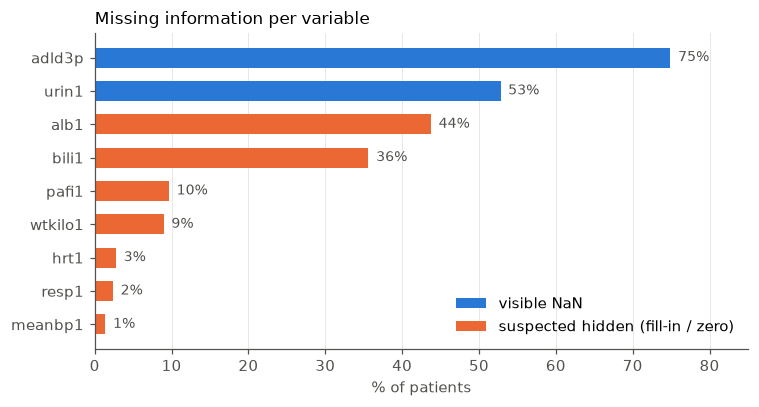

In [14]:
hidden = pd.Series(
    {
        "alb1": filled["alb1_filled"].mean(),
        "bili1": filled["bili1_filled"].mean(),
        "pafi1": filled["pafi1_filled"].mean(),
        "wtkilo1": (df["wtkilo1"] == 0).mean(),
        "hrt1": (df["hrt1"] == 0).mean(),
        "resp1": (df["resp1"] == 0).mean(),
        "meanbp1": (df["meanbp1"] == 0).mean(),
    }
)
visible = df[["adld3p", "urin1"]].isna().mean()

overview = (
    pd.DataFrame({"visible NaN": visible, "suspected hidden": hidden}).fillna(0) * 100
)
overview = overview.loc[overview.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(
    overview.index,
    overview["visible NaN"],
    color=COLOR_NO_RHC,
    label="visible NaN",
    height=0.6,
)
ax.barh(
    overview.index,
    overview["suspected hidden"],
    left=overview["visible NaN"],
    color=COLOR_RHC,
    label="suspected hidden (fill-in / zero)",
    height=0.6,
)
for i, total in enumerate(overview.sum(axis=1)):
    ax.text(total + 1, i, f"{total:.0f}%", va="center", fontsize=9, color=TEXT_MUTED)
ax.set_xlabel("% of patients")
ax.set_xlim(0, 85)
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Missing information per variable", loc="left", fontsize=11)
plt.tight_layout()
plt.show()

### 1.9 Is "not measured" informative?

Missingness only threatens a causal analysis if it is related to treatment or outcome. For each missingness indicator we compare the **RHC rate** and the **30-day mortality** between patients with and without it.

If a missingness indicator is associated with both $A$ and $Y$, then "being measured" carries clinical information: a lab is ordered more often for sicker patients, or a catheter is placed more often when the measurement is taken. Dropping those patients, or imputing naively, could then bias the effect estimate.

In [15]:
indicators = pd.concat(
    [
        filled,
        pd.DataFrame(
            {
                "wtkilo1_zero": df["wtkilo1"] == 0,
                "urin1_missing": df["urin1"].isna(),
                "adld3p_missing": df["adld3p"].isna(),
            }
        ),
    ],
    axis=1,
)

rows = []
for name, flag in indicators.items():
    rows.append(
        {
            "indicator": name,
            "n_flagged": int(flag.sum()),
            "rhc_rate_flagged": rhc[flag].mean(),
            "rhc_rate_other": rhc[~flag].mean(),
            "mortality_flagged": died[flag].mean(),
            "mortality_other": died[~flag].mean(),
        }
    )
pd.DataFrame(rows).set_index("indicator").round(3)

,n_flagged,rhc_rate_flagged,rhc_rate_other,mortality_flagged,mortality_other
indicator,,,,,
alb1_filled,2509,0.399,0.366,0.343,0.328
bili1_filled,2043,0.395,0.373,0.320,0.343
pafi1_filled,554,0.265,0.393,0.233,0.345
wtkilo1_zero,515,0.293,0.389,0.346,0.333
urin1_missing,3028,0.357,0.407,0.339,0.330
adld3p_missing,4296,0.418,0.271,0.418,0.084


**Reading.** Three indicators stand out:

- **`adld3p` missing**: 30-day mortality is 41.8% when the value is missing and 8.4% when it is observed. Missingness this strongly tied to the outcome suggests that the value is only observed for patients who *survived long enough to be interviewed*. This is checked in 1.10.
- **`pafi1` filled**: these patients receive RHC less often (26.5% vs 39.3%) and die less often (23.3% vs 34.5%). A PaO₂/FiO₂ ratio requires an arterial blood gas, which is typically not drawn in less severe patients. Missingness therefore depends on severity, which is itself largely observed (`aps1`, `resp`, `cat1`). This is plausibly MAR given the covariates, but the indicator carries clinical judgement and is associated with both $A$ and $Y$.
- **`alb1`, `bili1` filled**: weak associations. Filling missing labs with a normal value is also the standard APACHE convention (a missing lab scores 0 points), which supports the fill-in hypothesis.

### 1.10 Follow-up checks

**`adld3p` and `das2d3pc`.** The `d3` in both names suggests a **day-3 interview**. If the ADL value requires the patient (or a surrogate) to be interviewed around day 3, patients who died before day 3 can never have it.

In [16]:
adl_missing = df["adld3p"].isna()
early_death = (df["t3d30"] <= 3) & (df["dth30"] == "Yes")

pd.DataFrame(
    {
        "n": adl_missing.value_counts(),
        "death_by_day_3": early_death.groupby(adl_missing).mean().round(3),
        "das2d3pc_distinct_values": df["das2d3pc"].groupby(adl_missing).nunique(),
    }
).rename(index={False: "adld3p observed", True: "adld3p missing"})

,n,death_by_day_3,das2d3pc_distinct_values
adld3p,,,
adld3p observed,1439,0.004,66
adld3p missing,4296,0.072,987


In [17]:
# Most frequent das2d3pc values in each group
for label, mask in [("adld3p observed", ~adl_missing), ("adld3p missing", adl_missing)]:
    top = df.loc[mask, "das2d3pc"].round(2).value_counts().head(5)
    print(f"{label:16s}", {value: int(n) for value, n in top.items()})

adld3p observed  {33.0: 182, 12.0: 121, 13.5: 97, 11.0: 83, 15.0: 57}
adld3p missing   {14.75: 414, 15.41: 370, 29.15: 293, 29.14: 208, 16.39: 141}


**Reading.**

- Among patients with `adld3p` observed, only 0.4% died by day 3, against 7.2% among the others. Observing `adld3p` is conditional on surviving to the interview, which happens *after* the treatment decision. Using it would mean **conditioning on a post-treatment event** (selection bias). → **Exclude `adld3p`.**
- `das2d3pc` has no `NaN`. When `adld3p` is observed it takes round values (33, 12, 13.5…), the raw questionnaire scores. When `adld3p` is missing it takes 987 distinct non-round values (14.75, 15.41, 29.15…), which look model-imputed. Its content (functional status two weeks *before* admission) is pre-treatment, and Connors et al. adjusted for it. → **Keep `das2d3pc`, and run a sensitivity analysis without it.**

**Zero vital signs.** Are the 60 patients with `meanbp1 = 0` and `hrt1 = 0` missing values or real cardiac arrests?

In [18]:
zero_vitals = (df["meanbp1"] == 0) & (df["hrt1"] == 0)

pd.DataFrame(
    {
        "n": zero_vitals.value_counts(),
        "resp1_also_zero": (df["resp1"] == 0).groupby(zero_vitals).mean(),
        "median_aps1": df["aps1"].groupby(zero_vitals).median(),
        "median_scoma1": df["scoma1"].groupby(zero_vitals).median(),
        "rhc_rate": rhc.groupby(zero_vitals).mean(),
        "mortality_30d": died.groupby(zero_vitals).mean(),
    }
).rename(index={False: "others", True: "zero BP and HR"}).round(3)

,n,resp1_also_zero,median_aps1,median_scoma1,rhc_rate,mortality_30d
others,5675,0.016,53.0,0.0,0.379,0.332
zero BP and HR,60,0.750,87.5,55.0,0.600,0.550


**Reading.** In 75% of these patients the respiratory rate is also 0. Their APACHE score is much higher (median 87.5 vs 53), they are often comatose (median coma score 55 vs 0), and 60% receive RHC. This is the profile of patients resuscitated from a **cardiopulmonary arrest**, not of random missing values. → **Keep the zeros, and add an indicator `cardiac_arrest`** so that linear models do not treat "0 mmHg" as the end of a continuous scale. A weight of 0 kg, on the other hand, is impossible. → **Set `wtkilo1 = 0` to missing, and add an indicator.**

### 1.11 Decisions from Part 1

These decisions are implemented in `src/rhc_causal_bayes/data.py` and checked by `tests/test_data.py`.

| Issue | Variables | Decision | Rationale |
|---|---|---|---|
| Post-treatment variables | `death`, `t3d30`, `dthdte`, `dschdte`, `lstctdte` | exclude | measured after the treatment decision |
| Interview-based, survival-dependent | `adld3p` | exclude | observed only for patients alive at the day-3 interview |
| Interview-based, partly imputed | `das2d3pc` | keep | pre-admission content; sensitivity analysis without it |
| Structural `NaN` | `cat2` | recode as `"None"` | no secondary category |
| Genuine `NaN` | `urin1` (53%) | median imputation + missing indicator | missingness associated with RHC |
| Suspected fill-ins | `alb1`, `bili1`, `pafi1` | keep values + fill-in indicators | "not measured" carries clinical information |
| Impossible zeros | `wtkilo1` | set to `NaN`, impute + indicator | weight cannot be 0 |
| Zero vital signs | `meanbp1`, `hrt1`, `resp1` | keep + `cardiac_arrest` indicator | profile of real arrests |
| Implausible values | `alb1 > 10` (2), `edu > 25` (3) | set to `NaN`, then impute | physiologically impossible or implausible |

All missingness indicators are **pre-treatment** (they describe what was measured on day 1), so they are legitimate adjustment variables.

## 2. Univariate distributions

### 2.1 Binary variables

Prevalence of admission diagnoses, comorbidities and DNR status. Very rare conditions matter for two reasons. A category with a handful of patients can end up empty in a cross-fitting fold. It can also create positivity problems if all of its patients received the same treatment.

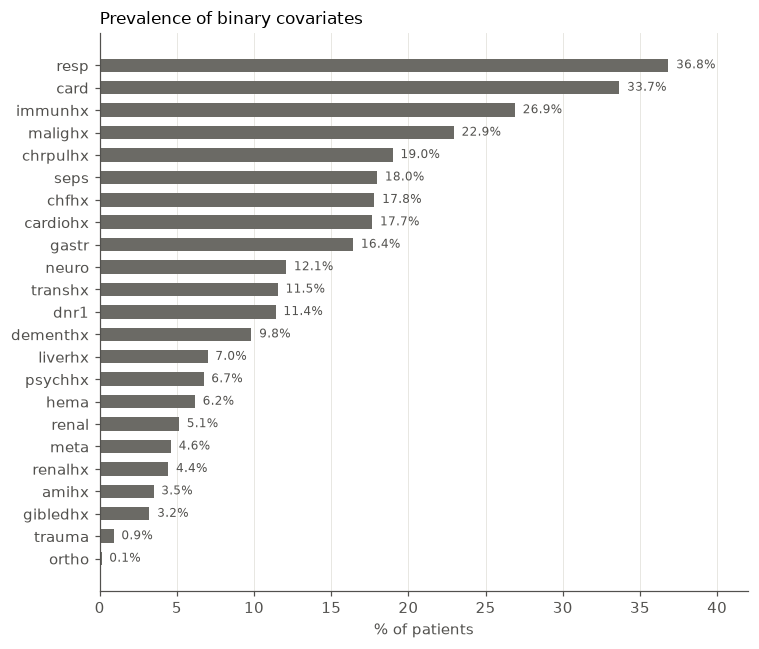

In [19]:
BINARY = (
    VARIABLE_GROUPS["admission_diagnosis"] + VARIABLE_GROUPS["comorbidity"] + ["dnr1"]
)

# "Yes"/"No" and 1/0 columns -> proportion of "Yes" or 1
prevalence = df[BINARY].astype(str).isin(["Yes", "1"]).mean().sort_values()

COLOR_ALL = "#6b6a65"  # neutral grey: all patients, no treatment split

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(prevalence.index, 100 * prevalence, color=COLOR_ALL, height=0.6)
for i, value in enumerate(prevalence):
    ax.text(
        100 * value + 0.5,
        i,
        f"{100 * value:.1f}%",
        va="center",
        fontsize=8,
        color=TEXT_MUTED,
    )
ax.set_xlabel("% of patients")
ax.set_xlim(0, 42)
ax.grid(axis="y", visible=False)
ax.set_title("Prevalence of binary covariates", loc="left", fontsize=11)
plt.tight_layout()
plt.show()

**Reading.** `ortho` (7 patients, 0.1%) and `trauma` (52, 0.9%) are extremely rare. Most comorbidities lie between 3% and 27%. The two most common admission diagnoses are respiratory (37%) and cardiovascular (34%).

### 2.2 Categorical variables

In [20]:
CATEGORICAL = ["cat1", "cat2", "ca", "sex", "race", "income", "ninsclas"]

tables = {}
for col in CATEGORICAL:
    counts = df[col].fillna("None").value_counts()
    tables[col] = pd.DataFrame({"n": counts, "pct": (100 * counts / len(df)).round(1)})

pd.concat(tables, names=["variable", "level"])

n   pct
variable level                          
cat1     ARF                  2490  43.4
         MOSF w/Sepsis        1227  21.4
         COPD                  457   8.0
         CHF                   456   8.0
         Coma                  436   7.6
         MOSF w/Malignancy     399   7.0
         Cirrhosis             224   3.9
         Lung Cancer            39   0.7
         Colon Cancer            7   0.1
cat2     None                 4535  79.1
         MOSF w/Sepsis         826  14.4
         MOSF w/Malignancy     229   4.0
         Coma                   90   1.6
         Cirrhosis              38   0.7
         Lung Cancer            15   0.3
         Colon Cancer            2   0.0
ca       No                   4379  76.4
         Yes                   972  16.9
         Metastatic            384   6.7
sex      Male                 3192  55.7
         Female               2543  44.3
race     white                4460  77.8
         black                 920  16.0
         other                 355   6.2
income   Under $11k           3226  56.3
         $11-$25k             1165  20.3
         $25-$50k              893  15.6
         > $50k                451   7.9
ninsclas Private              1698  29.6
         Medicare             1458  25.4
         Private & Medicare   1236  21.6
         Medicaid              647  11.3
         Medicare & Medicaid   374   6.5
         No insurance          322   5.6

**Reading.**

- `cat1` is dominated by ARF (43%) and MOSF with sepsis (21%). Colon cancer (7 patients) and lung cancer (39) are tiny groups. In the hierarchical Bayesian model (week 4), these groups will borrow strength from the others through **partial pooling**.
- `income` is ordinal (four ordered brackets), and 56% of patients are in the lowest one.
- `ninsclas` combines two pieces of information: age-related eligibility (Medicare) and poverty (Medicaid).

### 2.3 Continuous variables

One histogram per continuous variable (`adld3p` excluded). Vertical dashed lines mark the suspected fill-in values found in 1.5.

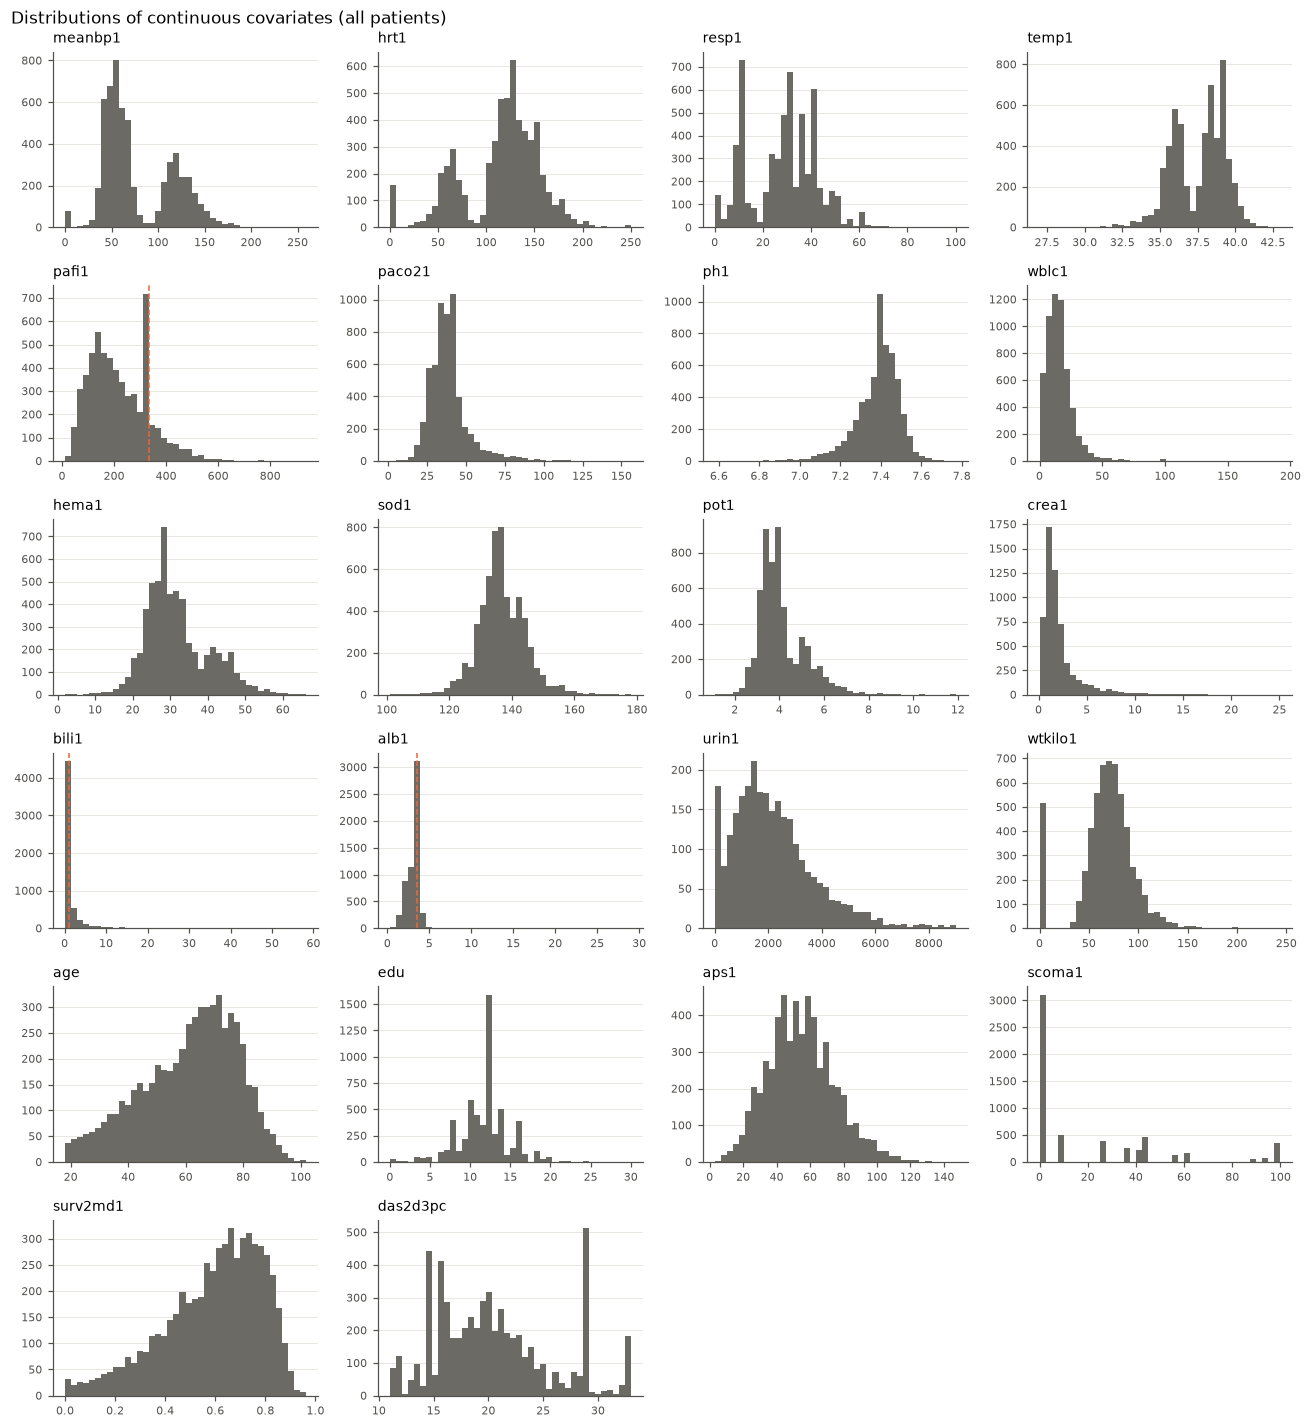

In [21]:
CONTINUOUS_KEPT = [col for col in CONTINUOUS if col != "adld3p"]

n_cols = 4
n_rows = int(np.ceil(len(CONTINUOUS_KEPT) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 2.2 * n_rows))

for ax, col in zip(axes.flat, CONTINUOUS_KEPT):
    ax.hist(df[col].dropna(), bins=40, color=COLOR_ALL)
    if col in SUSPECTED_FILL_INS:
        ax.axvline(
            SUSPECTED_FILL_INS[col], color=COLOR_RHC, linestyle="--", linewidth=1
        )
    ax.set_title(col, loc="left", fontsize=9)
    ax.tick_params(labelsize=7)
    ax.grid(axis="x", visible=False)

for ax in axes.flat[len(CONTINUOUS_KEPT) :]:
    ax.set_visible(False)

fig.suptitle(
    "Distributions of continuous covariates (all patients)",
    x=0.01,
    ha="left",
    fontsize=11,
)
plt.tight_layout()
plt.show()

**Reading: bimodal vital signs.** `meanbp1` has two modes (around 55 and 120 mmHg), and so do `hrt1` (≈ 60 and 130), `temp1` (≈ 36 and 39 °C), `hema1` and `pot1`. `resp1` has spikes at 10 and 40.

Real physiology in a population is not bimodal like this. The explanation is the **APACHE recording convention**: for each variable, the value recorded on day 1 is the *worst* value of the first 24 hours, i.e. the one farthest from normal. A patient in shock is recorded with a low blood pressure, a hypertensive patient with a high one, and the normal middle is under-represented.

**Consequence for modeling.** Risk is **U-shaped** in these variables: both low and high values are dangerous. A logistic regression with a linear term in `meanbp1` is therefore misspecified. Two fixes are possible: flexible terms (splines), or models that learn the shape themselves (the boosting used by DML in week 3). This is a concrete, data-driven argument for DML, which we will check in Part 4 (mortality vs covariates).

Other remarks:

- `scoma1` takes a few discrete values (0, 9, 26, 37, 41, 44, 55, 61, 89, 94, 100), so it is an ordinal score rather than a continuous one.
- `urin1` has a spike at 0 (anuria, 60 patients).
- `wtkilo1` has its isolated spike at 0 (the 515 impossible values).

### 2.4 Skewness and log transformation

Linear models (logistic regression for the propensity score and the outcome, and the Bayesian model later) are sensitive to long right tails: a few extreme values get a large leverage. A standard remedy for positive, right-skewed lab values is $\log(1 + x)$. Tree-based models (DML, week 3) are invariant to monotone transformations, so this only matters for linear models.

We compare the sample skewness before and after the transformation.

In [22]:
skewness = pd.DataFrame(
    {
        "skew_raw": df[CONTINUOUS_KEPT].skew(),
        "skew_log1p": np.log1p(df[CONTINUOUS_KEPT].clip(lower=0)).skew(),
    }
).round(2)
skewness.sort_values("skew_raw", key=abs, ascending=False).head(10)

,skew_raw,skew_log1p
alb1,5.99,-0.98
bili1,5.60,2.39
wblc1,3.54,-1.02
crea1,3.20,1.19
paco21,2.17,0.07
scoma1,1.41,0.36
pot1,1.27,0.59
ph1,-1.22,-1.30
urin1,1.09,-3.17
pafi1,0.80,-0.56


**Reading.**

- `bili1` (5.6 → 2.4), `wblc1` (3.5 → −1.0) and `crea1` (3.2 → 1.2) are strongly right-skewed lab values, and the log reduces their skewness a lot. → **Candidates for `log1p`** in linear models.
- `alb1` has a raw skewness of 6.0, but only because of the two impossible values (11 and 29 g/dL). Once they are removed (1.11), no transformation is needed.
- `paco21` (2.2 → 0.1): also a candidate.
- For variables that are roughly symmetric (`sod1`, `aps1`, `age`…), the log makes things *worse*. We leave them untransformed.

### 2.5 Summary of Part 2

| Finding | Consequence |
|---|---|
| Rare levels: `ortho` (7), `Colon Cancer` (7), `Lung Cancer` (39), `trauma` (52) | check positivity (Part 6); partial pooling in the Bayesian model |
| `bili1`, `crea1`, `wblc1`, `paco21` right-skewed | `log1p` in linear models |
| Fill-in spikes visible in `alb1`, `bili1`, `pafi1` | confirms the indicators decided in 1.11 |
| Bimodal vital signs (worst value of 24 h, APACHE convention) | U-shaped risk: linear terms misspecified → splines or boosting (DML) |
| `scoma1` takes few discrete values | treat as ordinal |

## 3. Treatment vs covariates: measuring confounding by indication

From here on we use the **cleaned data** (`make data`), i.e. the same covariates `X` that the causal models will receive: categoricals one-hot encoded, skewed labs log-transformed, missing values imputed, indicators added.

In [23]:
from rhc_causal_bayes.data import design_matrix, load_clean

clean_df = load_clean()  # data/processed/rhc_clean.parquet, written by `make data`
X, a, y, group = design_matrix(clean_df)
print(f"X: {X.shape[0]} patients x {X.shape[1]} covariates")

X: 5735 patients x 79 covariates


### 3.1 Standardized mean differences (SMD)

For each covariate $x$, the SMD compares the two arms on a scale that does not depend on the units:

$$\text{SMD} = \frac{\bar x_1 - \bar x_0}{\sqrt{(s_1^2 + s_0^2)/2}}$$

where index 1 is RHC and 0 is no RHC. For a 0/1 variable the mean is a proportion and $s^2 = p(1-p)$. Unlike a t-test, the SMD does not grow with $n$: it measures the **size** of the imbalance, not its significance. The usual rule of thumb is $|\text{SMD}| < 0.1$ for "balanced".

In [24]:
def standardized_mean_difference(X: pd.DataFrame, a: np.ndarray) -> pd.Series:
    """SMD per column: (mean treated - mean control) / pooled standard deviation."""
    treated, control = X[a == 1], X[a == 0]
    pooled_sd = np.sqrt((treated.var() + control.var()) / 2)
    return (treated.mean() - control.mean()) / pooled_sd


smd = standardized_mean_difference(X, a)
table1 = pd.DataFrame(
    {
        "mean_no_rhc": X[a == 0].mean(),
        "mean_rhc": X[a == 1].mean(),
        "smd": smd,
    }
).sort_values("smd", key=abs, ascending=False)

print(f"Covariates with |SMD| > 0.1: {(smd.abs() > 0.1).sum()} of {len(smd)}")
table1.head(20).round(3)

Covariates with |SMD| > 0.1: 39 of 79


,mean_no_rhc,mean_rhc,smd
aps1,50.934,60.739,0.501
meanbp1,84.869,68.198,-0.455
pafi1,240.627,192.433,-0.433
cat1_MOSF w/Sepsis,0.148,0.321,0.415
log_crea1,0.944,1.122,0.387
neuro,0.162,0.054,-0.353
cat1_COPD,0.112,0.027,-0.342
card,0.284,0.423,0.295
alb1,3.161,2.966,-0.279
resp,0.417,0.289,-0.270


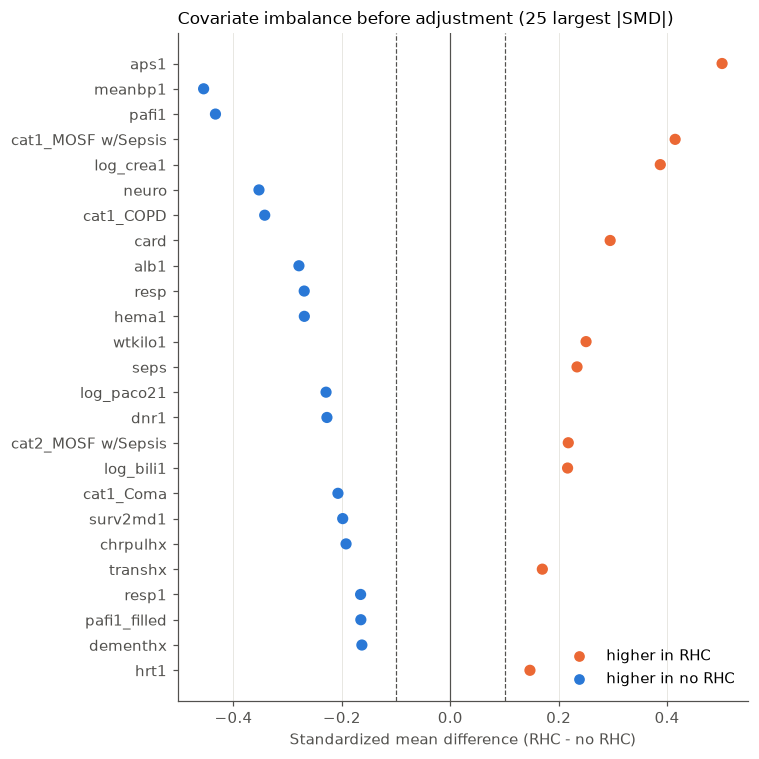

In [25]:
top = table1.head(25).iloc[::-1]  # largest at the top of the plot
colors = np.where(top["smd"] > 0, COLOR_RHC, COLOR_NO_RHC)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(top["smd"], top.index, c=colors, s=40, zorder=3)
for x in (-0.1, 0.1):
    ax.axvline(x, color=TEXT_MUTED, linestyle="--", linewidth=0.8)
ax.axvline(0, color=TEXT_MUTED, linewidth=0.8)
ax.set_xlabel("Standardized mean difference (RHC - no RHC)")
ax.grid(axis="y", visible=False)
ax.set_title(
    "Covariate imbalance before adjustment (25 largest |SMD|)", loc="left", fontsize=11
)
ax.scatter([], [], c=COLOR_RHC, label="higher in RHC")
ax.scatter([], [], c=COLOR_NO_RHC, label="higher in no RHC")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

**Reading.** 39 of the 79 covariates have $|\text{SMD}| > 0.1$. The imbalance is large, and **it does not go in a single direction**:

- **RHC patients are physiologically sicker.** Their APACHE score is higher (SMD +0.50), their blood pressure (−0.46) and oxygenation (`pafi1`, −0.43) are lower, they have more sepsis-related organ failure (`cat1_MOSF w/Sepsis`, +0.42) and a worse renal function (`log_crea1`, +0.39).
- **But RHC is used less often** for neurological patients (`neuro`, −0.35), coma (−0.21), COPD (−0.34) and patients with a do-not-resuscitate order (`dnr1`, −0.23). These are very sick patients too, but ones for whom the catheter is not expected to help.

Clinicians seem to select patients who are sick *and* considered salvageable, with a cardiovascular or septic problem. As a result, the predicted 2-month survival `surv2md1` differs only moderately (−0.20) despite the large APACHE gap. We cannot guess the sign of the confounding bias in advance: some confounders push the crude difference up, others push it down. Part 5 illustrates this.

## 4. Outcome vs covariates: prognostic factors

### 4.1 Mortality and RHC rate by disease category

In [26]:
by_category = clean_df.groupby("cat1", observed=True).agg(
    n=("Y", "size"), mortality_30d=("Y", "mean"), rhc_rate=("A", "mean")
)
by_category.round(3)

,n,mortality_30d,rhc_rate
cat1,,,
ARF,2490,0.300,0.365
MOSF w/Sepsis,1227,0.344,0.570
COPD,457,0.175,0.127
CHF,456,0.127,0.458
Coma,436,0.656,0.218
MOSF w/Malignancy,399,0.541,0.396
Cirrhosis,224,0.420,0.219
Lung Cancer,39,0.385,0.128
Colon Cancer,7,0.143,0.143


**Reading.** Coma has the highest mortality (66%) but one of the lowest RHC rates (22%). CHF has a low mortality (13%) but a high RHC rate (46%). The disease category is therefore associated with $A$ and $Y$ in **opposite** directions, a textbook confounder that pulls the crude difference *down*.

### 4.2 Mortality across deciles of continuous covariates

For each variable we cut the patients into 10 groups of equal size and plot the 30-day mortality of each group against the median of the variable in the group. This is a non-parametric look at the shape of $\mathbb{P}(Y = 1 \mid x)$.

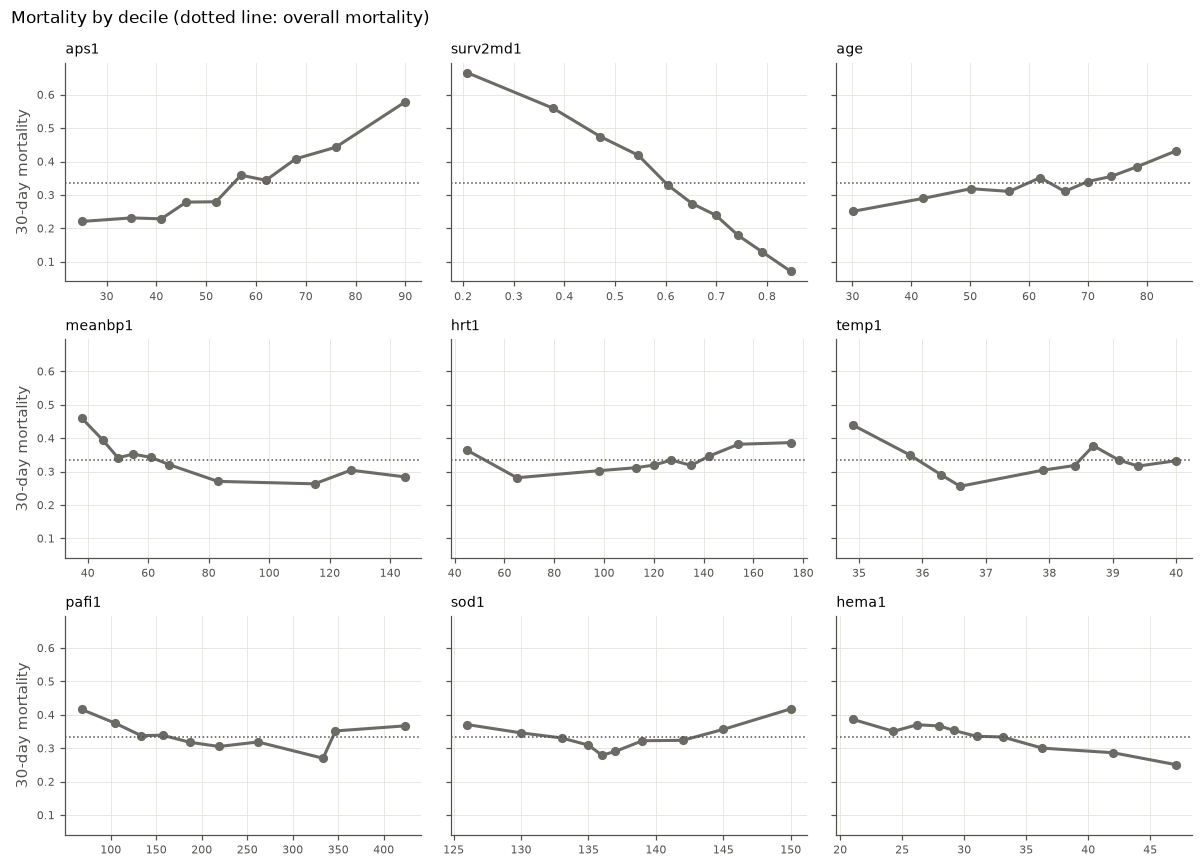

In [27]:
SHAPE_VARIABLES = [
    "aps1",
    "surv2md1",
    "age",
    "meanbp1",
    "hrt1",
    "temp1",
    "pafi1",
    "sod1",
    "hema1",
]
overall_mortality = clean_df["Y"].mean()

fig, axes = plt.subplots(3, 3, figsize=(11, 8), sharey=True)
for ax, col in zip(axes.flat, SHAPE_VARIABLES):
    decile = pd.qcut(clean_df[col], 10, duplicates="drop")
    grouped = clean_df.groupby(decile, observed=True).agg(
        x=(col, "median"), mortality=("Y", "mean")
    )
    ax.plot(
        grouped["x"],
        grouped["mortality"],
        color=COLOR_ALL,
        marker="o",
        markersize=5,
        linewidth=2,
    )
    ax.axhline(overall_mortality, color=TEXT_MUTED, linestyle=":", linewidth=1)
    ax.set_title(col, loc="left", fontsize=9)
    ax.tick_params(labelsize=7)
for ax in axes[:, 0]:
    ax.set_ylabel("30-day mortality")
fig.suptitle(
    "Mortality by decile (dotted line: overall mortality)",
    x=0.01,
    ha="left",
    fontsize=11,
)
plt.tight_layout()
plt.show()

**Reading.**

- **Monotone relations.** Mortality rises from 22% to 58% across `aps1` deciles and falls from 67% to 7% across `surv2md1` deciles, so both scores are very prognostic. Mortality also rises with age.
- **U-shaped relations.** For `temp1` (44% for hypothermia, 26% near normal, 38% for fever), `sod1` (37% → 28% → 42%), `hrt1` and `pafi1`, the risk is highest at both extremes. This confirms what the bimodal histograms of Part 2 suggested: a logistic regression that is linear in these variables is misspecified.
- `meanbp1` is mostly decreasing: low blood pressure (shock) is the most dangerous extreme.

## 5. Treatment–outcome association: crude and stratified

### 5.1 Risk difference within strata

Within a stratum $s$, $\widehat{\text{RD}}_s = \hat p_{1,s} - \hat p_{0,s}$, with the Wald standard error $\sqrt{\hat p_1(1-\hat p_1)/n_1 + \hat p_0(1-\hat p_0)/n_0}$. If the stratifying variable were the only confounder, $\widehat{\text{RD}}_s$ would be the causal effect in stratum $s$.

In [28]:
def risk_difference(d: pd.DataFrame) -> pd.Series:
    """Crude RD of Y between A = 1 and A = 0, with a 95% Wald interval."""
    y1, y0 = d.loc[d["A"] == 1, "Y"], d.loc[d["A"] == 0, "Y"]
    p1, p0 = y1.mean(), y0.mean()
    se = np.sqrt(p1 * (1 - p1) / len(y1) + p0 * (1 - p0) / len(y0))
    rd = p1 - p0
    return pd.Series(
        {
            "n": len(d),
            "n_rhc": len(y1),
            "rd": rd,
            "low": rd - 1.96 * se,
            "high": rd + 1.96 * se,
        }
    )


crude_rd = risk_difference(clean_df)
clean_df["aps1_quintile"] = pd.qcut(
    clean_df["aps1"],
    5,
    labels=["Q1 (least severe)", "Q2", "Q3", "Q4", "Q5 (most severe)"],
)

rd_by_category = clean_df.groupby("cat1", observed=True)[["A", "Y"]].apply(
    risk_difference
)
rd_by_severity = clean_df.groupby("aps1_quintile", observed=True)[["A", "Y"]].apply(
    risk_difference
)

print(
    f"Crude RD: {crude_rd['rd']:+.3f}  [{crude_rd['low']:+.3f}, {crude_rd['high']:+.3f}]"
)
pd.concat({"cat1": rd_by_category, "aps1 quintile": rd_by_severity}).round(3)

Crude RD: +0.074  [+0.048, +0.099]


n  n_rhc     rd    low   high
cat1          ARF                2490.0  909.0  0.069  0.031  0.107
              MOSF w/Sepsis      1227.0  700.0  0.117  0.065  0.170
              COPD                457.0   58.0  0.096 -0.023  0.214
              CHF                 456.0  209.0  0.048 -0.014  0.110
              Coma                436.0   95.0  0.117  0.016  0.218
              MOSF w/Malignancy   399.0  158.0  0.099  0.000  0.198
              Cirrhosis           224.0   49.0  0.194  0.038  0.350
              Lung Cancer          39.0    5.0 -0.212 -0.599  0.176
              Colon Cancer          7.0    1.0 -0.167 -0.465  0.132
aps1 quintile Q1 (least severe)  1230.0  302.0 -0.063 -0.114 -0.011
              Q2                 1070.0  313.0 -0.004 -0.061  0.053
              Q3                 1251.0  455.0  0.063  0.009  0.118
              Q4                 1080.0  484.0  0.044 -0.014  0.102
              Q5 (most severe)   1104.0  630.0  0.069  0.010  0.129

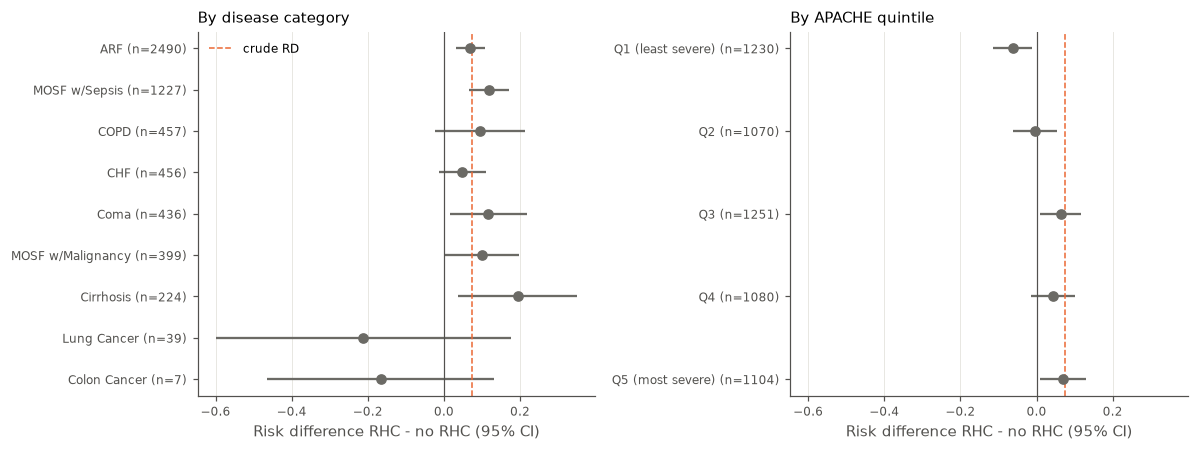

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True)
for ax, (title, table) in zip(
    axes,
    [("By disease category", rd_by_category), ("By APACHE quintile", rd_by_severity)],
):
    table = table.iloc[::-1]
    labels = [f"{name} (n={int(n)})" for name, n in zip(table.index, table["n"])]
    ax.errorbar(
        table["rd"],
        labels,
        xerr=[table["rd"] - table["low"], table["high"] - table["rd"]],
        fmt="o",
        color=COLOR_ALL,
        ecolor=COLOR_ALL,
        elinewidth=1.5,
        markersize=6,
        capsize=0,
    )
    ax.axvline(0, color=TEXT_MUTED, linewidth=0.8)
    ax.axvline(
        crude_rd["rd"], color=COLOR_RHC, linestyle="--", linewidth=1, label="crude RD"
    )
    ax.set_title(title, loc="left", fontsize=10)
    ax.grid(axis="y", visible=False)
    ax.tick_params(labelsize=8)
    ax.set_xlabel("Risk difference RHC - no RHC (95% CI)")
axes[0].legend(frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

**Reading.**

- **Within disease categories**, the RD stays positive in all the large categories, and is often *larger* than the crude +7.4 points (MOSF with sepsis +11.7, coma +11.7, cirrhosis +19.4). This is what Part 4.1 predicted: the disease category confounds *downwards*. The lung and colon cancer intervals are huge (5 and 1 treated patients).
- **Within APACHE quintiles**, the RD ranges from −6.3 points in the least severe quintile to about +6 in the most severe ones. APACHE confounds *upwards*. The trend may also hint at effect heterogeneity (week 5), but at this stage we cannot tell it apart from residual confounding.

### 5.2 Standardization by hand: a first non-parametric g-formula

Averaging the stratum-specific RDs with weights equal to the stratum sizes gives an estimate of the ATE, **if** the strata contain all the confounders:

$$\hat\psi_{\text{std}} = \sum_s \frac{n_s}{n}\, \widehat{\text{RD}}_s$$

This is exactly the g-formula $\mathbb{E}_X[\mu_1(X) - \mu_0(X)]$ with $X$ reduced to the stratum. It requires **positivity**: each stratum must contain both treated and untreated patients.

In [30]:
def standardized_rd(d: pd.DataFrame, strata: list[str]) -> tuple[float, int, int]:
    """Stratum-size-weighted RD. Returns (RD, n strata without both arms, n patients in them)."""
    rds, sizes, n_empty_strata, n_dropped = [], [], 0, 0
    for _, stratum in d.groupby(strata, observed=True):
        if stratum["A"].nunique() < 2:  # positivity violated in this stratum
            n_empty_strata += 1
            n_dropped += len(stratum)
            continue
        rds.append(
            stratum.loc[stratum["A"] == 1, "Y"].mean()
            - stratum.loc[stratum["A"] == 0, "Y"].mean()
        )
        sizes.append(len(stratum))
    return float(np.average(rds, weights=sizes)), n_empty_strata, n_dropped


rows = []
for strata in [["cat1"], ["aps1_quintile"], ["cat1", "aps1_quintile"]]:
    rd, n_empty, n_dropped = standardized_rd(clean_df, strata)
    rows.append(
        {
            "strata": " x ".join(strata),
            "standardized_rd": rd,
            "strata_without_both_arms": n_empty,
            "patients_dropped": n_dropped,
        }
    )
pd.DataFrame(rows).round(3)

,strata,standardized_rd,strata_without_both_arms,patients_dropped
0,cat1,0.088,0,0
1,aps1_quintile,0.021,0,0
2,cat1 x aps1_quintile,0.043,3,4


**Reading.**

| Adjustment | RD |
|---|---|
| none (crude) | +0.074 |
| `cat1` only | +0.088 (up: `cat1` confounds downwards) |
| APACHE quintile only | +0.021 (down: APACHE confounds upwards) |
| `cat1` × APACHE quintile | +0.043 (both effects combined) |

Adjusting for one or two variables already moves the estimate between +2.1 and +8.8 points. With 79 covariates, stratification is impossible: the strata would be almost all empty, the curse of dimensionality. This is exactly why we need **models**: the propensity score, outcome regression, AIPW and the Bayesian model. The combined stratification also leaves 3 strata (4 patients) without both arms: a first, tiny **positivity** violation.

## 6. Overlap preview

The propensity score $e(x) = \mathbb{P}(A = 1 \mid X = x)$ summarizes all covariates into one number. Positivity requires $0 < e(x) < 1$: every type of patient must have a real chance of receiving each treatment.

> **Preview only.** The model is a quick logistic regression fitted and evaluated on the same data, without cross-fitting. The proper propensity-score analysis comes in `frequentist.py`.

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ps_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
ps = ps_model.fit(X, a).predict_proba(X)[:, 1]

print(f"AUC of the propensity model: {roc_auc_score(a, ps):.3f}")
outside = (ps < 0.1) | (ps > 0.9)
print(
    f"Share with e(x) outside [0.1, 0.9]: {outside.mean():.1%} (RHC: {outside[a == 1].mean():.1%}, no RHC: {outside[a == 0].mean():.1%})"
)

AUC of the propensity model: 0.814
Share with e(x) outside [0.1, 0.9]: 19.3% (RHC: 6.8%, no RHC: 27.0%)


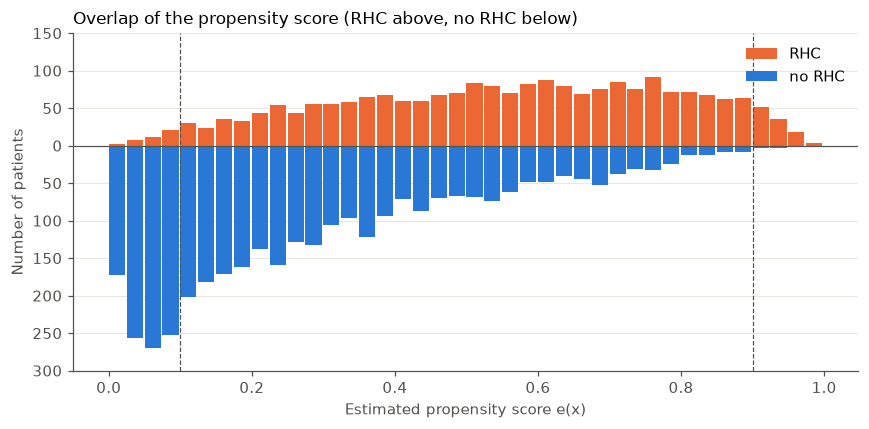

In [32]:
bins = np.linspace(0, 1, 41)
counts_rhc, _ = np.histogram(ps[a == 1], bins=bins)
counts_no, _ = np.histogram(ps[a == 0], bins=bins)
width = bins[1] - bins[0]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(
    bins[:-1], counts_rhc, width=width * 0.9, align="edge", color=COLOR_RHC, label="RHC"
)
ax.bar(
    bins[:-1],
    -counts_no,
    width=width * 0.9,
    align="edge",
    color=COLOR_NO_RHC,
    label="no RHC",
)
ax.axhline(0, color=TEXT_MUTED, linewidth=0.8)
for x in (0.1, 0.9):
    ax.axvline(x, color=TEXT_MUTED, linestyle="--", linewidth=0.8)
ax.set_yticks(ax.get_yticks())
ax.set_yticklabels([f"{abs(int(t))}" for t in ax.get_yticks()])
ax.set_xlabel("Estimated propensity score e(x)")
ax.set_ylabel("Number of patients")
ax.set_title(
    "Overlap of the propensity score (RHC above, no RHC below)", loc="left", fontsize=11
)
ax.legend(frameon=False, loc="upper right")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Reading.**

- An AUC of 0.81 means that the covariates predict the treatment well. The treatment decision is largely driven by what we observe, which is good news for the no-unmeasured-confounding assumption, but it also means the two groups are far apart.
- The two distributions overlap on most of $[0, 1]$, but **27% of the untreated patients have $e(x) < 0.1$**: patients who almost never receive RHC (typically coma, COPD, DNR). For them, the data contain very few comparable treated patients, so any estimate of their effect relies on extrapolation.
- 19% of all patients fall outside $[0.1, 0.9]$. Trimming them (Crump et al.) would stabilize the estimators but **change the estimand** to the overlap population. We will report both, as planned in the guide.

## 7. Correlations between continuous covariates

We use **Spearman** correlations (correlation of ranks). They capture any monotone relation and are robust to the skewed distributions and outliers seen in Part 2.

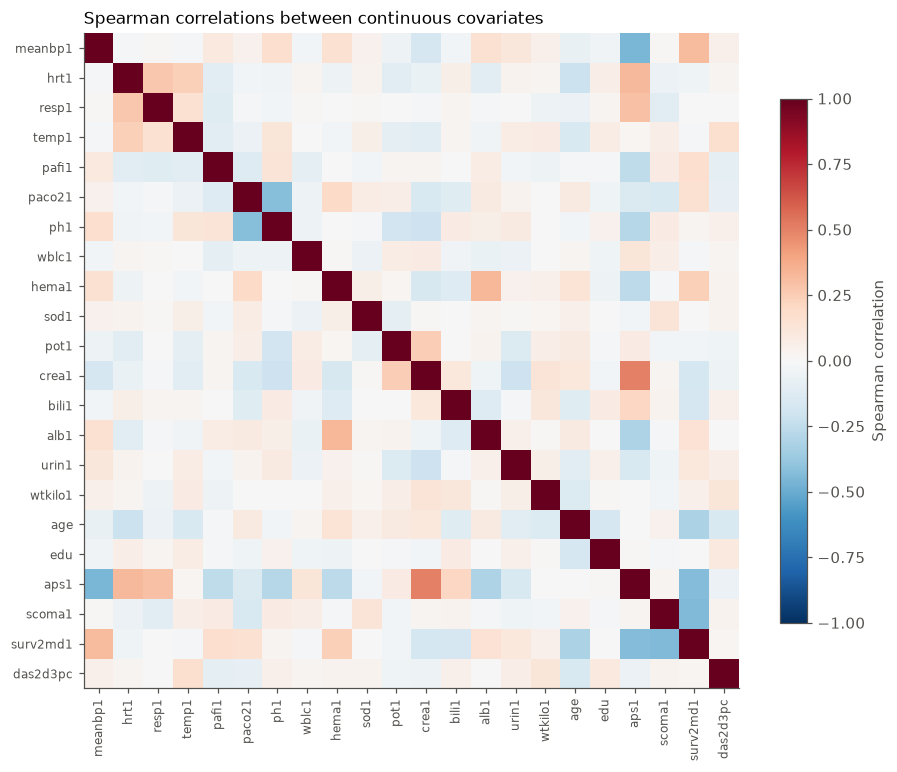

In [33]:
CONTINUOUS_CLEAN = [col for col in CONTINUOUS if col != "adld3p"]
spearman = clean_df[CONTINUOUS_CLEAN].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8.5, 7))
image = ax.imshow(spearman, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(CONTINUOUS_CLEAN)), CONTINUOUS_CLEAN, rotation=90, fontsize=8)
ax.set_yticks(range(len(CONTINUOUS_CLEAN)), CONTINUOUS_CLEAN, fontsize=8)
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.8, label="Spearman correlation")
ax.set_title(
    "Spearman correlations between continuous covariates", loc="left", fontsize=11
)
plt.tight_layout()
plt.show()

In [34]:
upper = np.triu(np.ones(spearman.shape, dtype=bool), k=1)  # each pair once
pairs = spearman.where(upper).stack().rename("spearman")
pairs.sort_values(key=abs, ascending=False).head(10).round(2).to_frame()

,,spearman
crea1,aps1,0.50
meanbp1,aps1,-0.46
scoma1,surv2md1,-0.44
aps1,surv2md1,-0.44
paco21,ph1,-0.43
hema1,alb1,0.33
hrt1,aps1,0.33
meanbp1,surv2md1,0.32
age,surv2md1,-0.31
alb1,aps1,-0.31


**Reading.** The strongest correlation is only 0.50 (`aps1` and `crea1`). Next come `aps1` with `meanbp1` (−0.46) and `surv2md1` with `aps1` and `scoma1` (−0.44 each). There is **no severe collinearity**. `surv2md1`, although built from other covariates by the SUPPORT model, is far from redundant with any single one of them. Keeping all covariates is reasonable. Regularization (penalized logistic regression, the horseshoe prior in the Bayesian model) will handle the moderate correlations.

## 8. Conclusions of the EDA

| # | Finding | Consequence for the modeling |
|---|---|---|
| 1 | Post-treatment variables and a survival-dependent one (`adld3p`) | excluded in `data.py`, tested |
| 2 | Hidden missing values (fill-ins), zero vital signs, impossible values | indicators, imputation, `cardiac_arrest` flag (`data.py`) |
| 3 | Crude RD +7.4 points; 39/79 covariates with \|SMD\| > 0.1 | strong confounding: adjustment is essential |
| 4 | Confounders act in **both directions** (APACHE up, disease category down) | the sign of the bias cannot be guessed; two-variable standardization already moves the RD from +8.8 to +4.3 points |
| 5 | U-shaped risk in vital signs (worst-value convention) | linear logistic models are misspecified → splines or boosting (DML) |
| 6 | Propensity AUC 0.81; 27% of untreated with $e(x) < 0.1$ | positivity is limited: diagnostics, trimming, report the overlap estimand too |
| 7 | Tiny categories (colon cancer n=7, lung cancer n=39) | partial pooling in the hierarchical Bayesian model |
| 8 | No severe collinearity | keep all pre-treatment covariates, with regularization |

**Next step:** the known-truth simulator and the cross-fitted AIPW (`simulate.py`, `frequentist.py`).